In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "raw" / "heart.csv"
OUT = ROOT / "outputs" / "figures"
OUT.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA).drop_duplicates()

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
display(df.head())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (302, 14)

First 5 Rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0



Statistical Summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000,302.000000
mean,54.42053,0.682119,0.963576,131.602649,246.500000,0.149007,0.526490,149.569536,0.327815,1.043046,1.397351,0.718543,2.314570,0.543046
std,9.04797,0.466426,1.032044,17.563394,51.753489,0.356686,0.526027,22.903527,0.470196,1.161452,0.616274,1.006748,0.613026,0.498970
min,29.00000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.00000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.250000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.50000,1.000000,1.000000,130.000000,240.500000,0.000000,1.000000,152.500000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.00000,1.000000,2.000000,140.000000,274.750000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.00000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


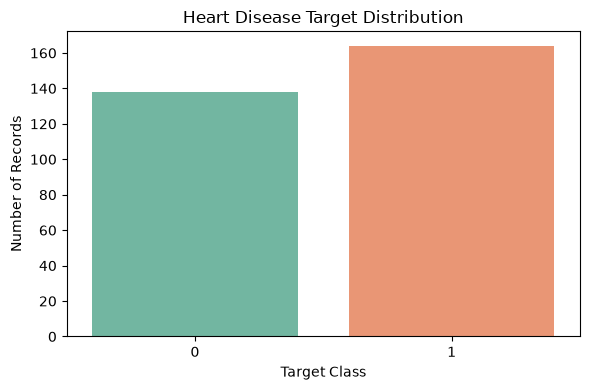

In [3]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="target", hue="target",
              palette="Set2", legend=False)

plt.title("Heart Disease Target Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig(OUT / "target_distribution.png", dpi=300)
plt.show()

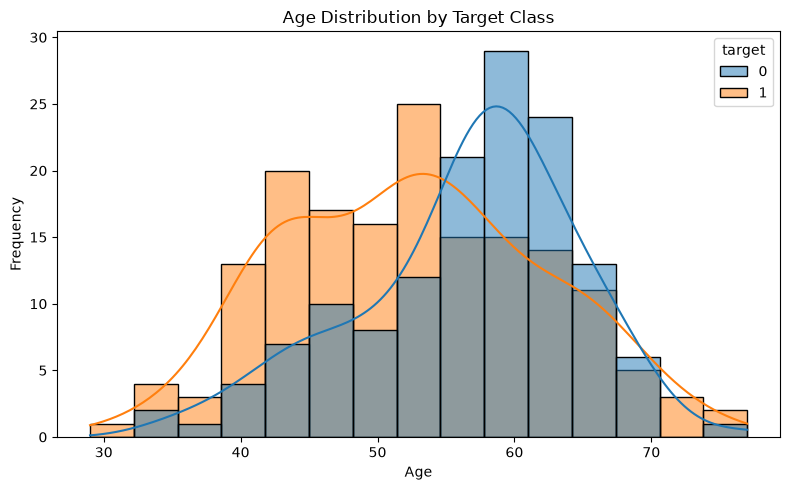

In [4]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    hue="target",
    kde=True,
    bins=15,
    alpha=0.5
)

plt.title("Age Distribution by Target Class")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(OUT / "age_distribution.png", dpi=300)
plt.show()

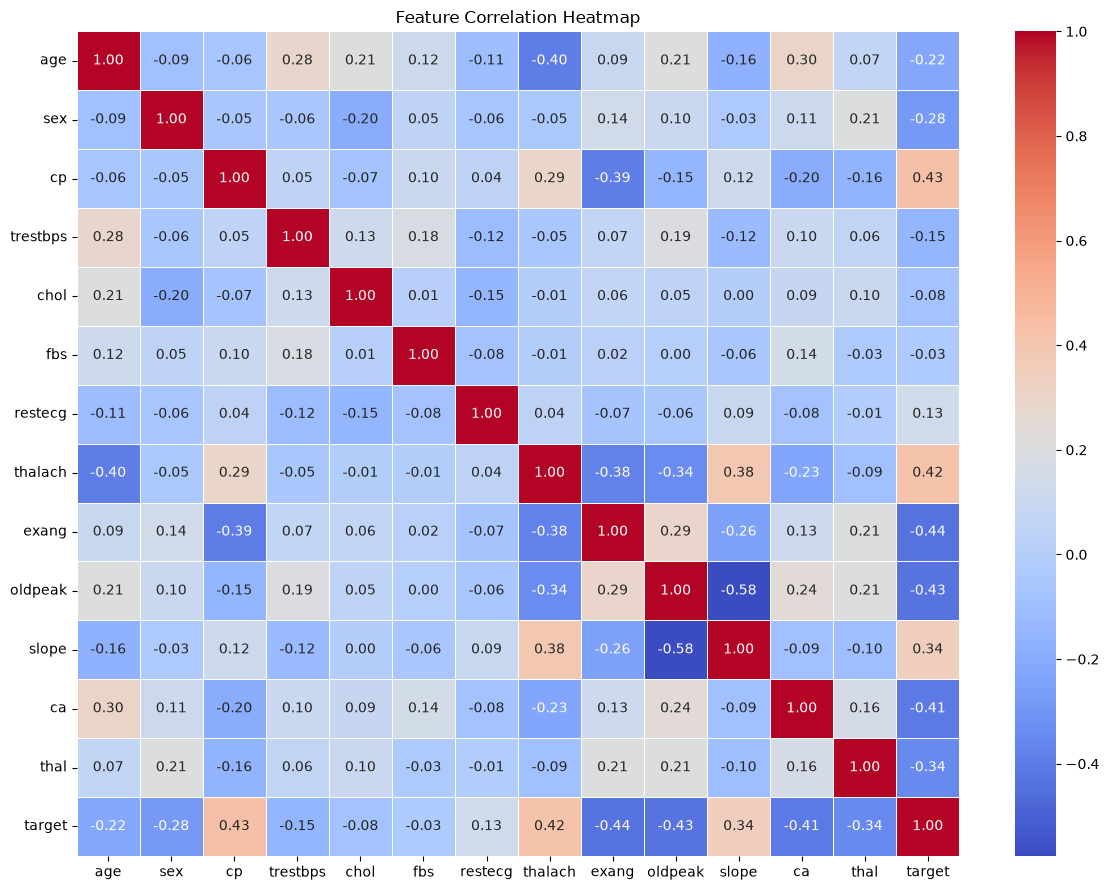

In [5]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()

plt.savefig(OUT / "correlation_heatmap.png", dpi=300)
plt.show()

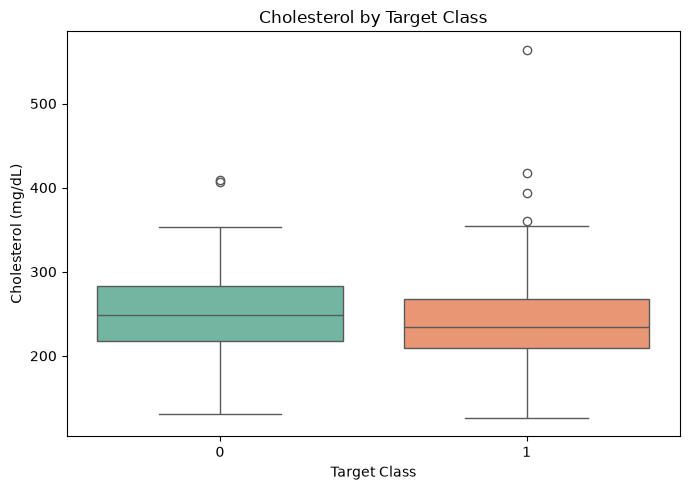

In [6]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="target",
    y="chol",
    hue="target",
    palette="Set2",
    legend=False
)

plt.title("Cholesterol by Target Class")
plt.xlabel("Target Class")
plt.ylabel("Cholesterol (mg/dL)")
plt.tight_layout()

plt.savefig(OUT / "cholesterol_boxplot.png", dpi=300)
plt.show()